# Leeds CityFM: current status

This notebook describes where the Leeds adaptation of CityFM stands now: the current model (**v5**), what it has learned, and how useful its embeddings are. Earlier models are summarised in one table (section 2). The full working, with all the evidence for the earlier decisions, is in `notebooks/archive/leeds_embeddings_2026-10-26.ipynb`.

| Section | What it covers |
|---|---|
| 1. Status | the current model and headline results |
| 2. How we got to v5 | earlier models, one line each |
| 3. Next steps | open items |
| 4. Background | how CityFM works, in plain terms |
| 5. Setup | |
| 6. Data | what the current model was trained on |
| 7. Training | did each stage learn? |
| 8. POI embeddings | what the text side captures |
| 9. Building embeddings | what the footprint side captures |
| 10. Population density | the first real test |
| Glossary | |

**Running it.** Run top to bottom. It needs `Leeds/Data/`, `Leeds_v2/Data/` (made by `python CityFM_collapse.py -c Leeds -o Leeds_v2`), `Leeds_v5/Model/` (model and log), and the population caches from `CityFM_pop_eval.py`. Results are cached in `Leeds/Analysis/`. The first run encodes for about 15 minutes; re-runs take a few minutes.

---
# 1. Status

*As of 27 October 2026.*

**The current model is v5** (`Leeds_v5/Model/model.pkl`).

| Part | How it was made |
|---|---|
| Inputs | the Leeds district from OSM, with the house-type buildings in each road context collapsed into one summary entry (`Leeds_v2/Data`, section 4.2) |
| Text | **names left out of all text**, in training and when the model is used. Each POI or building is read by its type tags only (e.g. `amenity: pub`) |
| Stage 1 (POI ↔ street) | 625 steps (5× the authors' default), learning-rate schedule fixed |
| Stage 2 (footprint ↔ type) | ResNet-18 starting from ImageNet weights, footprints drawn in metres, 1,250 steps |
| Stage 3 (street ↔ street) | 270 steps |

Trained from scratch on CPU on the research server (`CityFM_train.py --no-names`), in about 12 hours: stage 1 took 11 (64 s per step), stage 2 one.

**Headline results**

| Question | Answer | Section |
|---|---|---|
| Did stage 1 (POI ↔ street) learn? | **Yes.** With the POI held out, CityFM picks the right street out of 64 in 7.0% of quizzes (in the top 5: 23%), against 4.2% (14%) for untuned BERT reading the same name-free strings, and 1.6% for guessing | 7, 8a |
| Did stage 2 (footprint ↔ building type) learn? | **Yes.** A building's class can be read from its footprint embedding 57% of the time (18 classes), against 19% from floor area alone. Matching a footprint straight to the class text works 47% of the time (chance 6%) | 7, 9 |
| Did stage 3 (street ↔ street by bus routes) learn? | **Barely.** Its loss ends 4% of the way from guessing to the floor | 7 |
| What do the text embeddings capture? | **What a POI is, adjusted by what is found near it.** Categories that occur together in Leeds have become more similar (ρ 0.62, against 0.20 for untuned BERT), while the model keeps much of BERT's sense of which categories are related (ρ 0.17, against 0.44 for v1: categories are now arranged by what is found together in Leeds more than by their general meaning) | 8c |
| Are the embeddings useful for a real task? | **Not beyond simple counts.** On the fair population test (500 m grid), CityFM's features give R² 0.74, against 0.76 for 9 simple OSM counts and 0.80 for the counts plus position. Adding CityFM to the counts adds nothing | 10 |

**What this means.**

* All three fixes to training are in place (inputs, learning-rate schedule, no names), and stages 1 and 2 learn what they are asked to.
* Leaving names out keeps the text side honest. With names (v4), the model learned to recognise places from words like *Otley* in POI names, and stopped describing what POIs are. Without them, its gain on the street quiz is smaller but has to come from types and context.
* For population density, what the embeddings know is already in simple counts of buildings, houses and POIs. A harder task is needed to show whether they add anything (section 3).
* Stage 3 needs a new target.

# 2. How we got to v5

| Model | What changed | Why | What happened |
|---|---|---|---|
| **v1** (22-23 Sep) | the authors' code and settings | starting point | trained, but learned little: on the street quiz it was no better than untuned BERT, and the footprint branch and stage 3 learned nothing |
| **v2** (23 Oct) | house-type buildings in each context collapsed into one summary entry; ResNet starting from ImageNet weights; footprints drawn in metres | 80% of context entries were `building: house`; the image network started from random weights; footprints drawn in degrees were sheared | stage 1 beat untuned BERT on the street quiz for the first time; footprints improved a little |
| **v3a** (23-25 Oct) | learning-rate schedule fixed | in the authors' code the rate reached zero after 43 of 125 steps in stage 1, and 10 of 270 in stage 3 | stage 1 kept learning; stage 3 still learned nothing |
| **v3b** (23-25 Oct) | stages 1 and 2 trained 5× longer | losses were still falling | stage 2 improved most; stage 1 won the street quiz but its text side shifted from POI type towards location (section 8c). v4 keeps this text side |
| **v4** (26 Oct) | stage 2 retrained from v3b with names left out of its text, for twice as long, with the image network reset to ImageNet weights | 64% of stage-2 quiz texts contained a name, which an outline cannot predict | footprint class accuracy rose from 0.41 to 0.57 |
| **v5** (27 Oct) | retrained from scratch with names left out of all text (stage 1 as long as v3b's, stage 2 as long as v4's) | v3b/v4's text side had learned to recognise places from names: Otley Tavern's nearest neighbours were Otley Conservative Club, Otley Pharmacy and other Otley businesses, and a POI's category could be read from its neighbours only 36% of the time (v1-v3a: 0.89-0.97) | the street-quiz gain over BERT shrank (top-1 7.0% vs 13.9%) but now comes from types and context; co-occurrence ρ rose from 0.48 to 0.62; footprints as good as v4's |

**Population density** (section 10) was added along the way as the first real test. On the fair test (a 500 m grid), every model from v1 to v5 scored R² 0.75-0.77 with the authors' features, against 0.76 for 9 simple OSM counts and 0.80 for the counts plus position.

The code behind these changes: `CityFM_collapse.py` (v2 inputs), `config.vision_pretrained` and `config.raster_metric` (footprint branch), the schedule fix in `utils/training.py`, and the `CityFM_train.py` options `-e`, `-m`, `-s`, `-f`, `--reset-image`, `--no-names-stage2` (v4) and `--no-names` (v5).

# 3. Next steps

Open items, roughly in priority order.

### Downstream tasks
- [ ] **A task that simple counts cannot solve easily.** Candidates: the Index of Multiple Deprivation (IMD) by LSOA; dwelling built form and age band from Energy Performance Certificates (EPC), joined to OSM buildings through OS Open UPRN, which would test the footprint embeddings directly (EPC needs a free registration); DfT traffic flows (AADF), which would test the road contexts.

### Footprint branch (stage 2)
- [ ] **Merge house types in the stage-2 text** (`semidetached house`, `detached`, `bungalow`, `residential` → `building: house`). These tags mostly reflect mapping habit, so the quiz marks the model wrong for "errors" that are really labelling noise.
- [ ] **Feed floor area on a log scale.** Area enters as `min(area, 5000) / 5000`, so 95% of Leeds buildings fall between 0.007 and 0.042 on a 0-1 scale. The code already has a log version (`log_surface`). It changes what the model reads at encoding time, so it needs a flag saved with the model, like `raster_metric`.

### Road contexts (stages 1 and 3)
These change the text and road embeddings, which the population test barely responds to, so they are best tested with a road-based task. Without names, a road's context is now described only by the types of things near it, so adding the road's own type matters more.
- [ ] **Add the road's own type** (e.g. `highway: secondary`) to its context. Leave the name out: in stage 3, paired segments are often pieces of the same road.
- [ ] **Decide what to do with service roads and paths**: 38% and 9% of segments, so almost half of the "roads" are not streets.
- [ ] **Replace the stage-3 target.** Pairing streets by bus-route count teaches nothing (section 7). Candidates are network statistics such as closeness, betweenness or integration at a few radii (`momepy`, `cityseer`). Do not also put them in the context, or stage 3 becomes text matching.
- [ ] **Fix the stage-3 loop** at `utils/training.py:523`: the `continue` skips `idx += ...`, so a window with fewer than two pairs would loop forever. It has not triggered in Leeds.

### Scale
- [ ] National scale would need a new data layer. Pre-processing is O(segments × entities) pure Python, uses a single Overpass query, and keeps only entities within 50 km of the first one downloaded.

---
# 4. Background

## 4.1 The idea

Many urban analytics questions need a **numerical description of a place**: what is around this street, what is this building used for, what kind of neighbourhood is this? A **foundation model** is trained once, on a lot of *unlabelled* data, to turn things into **embeddings**: fixed-length lists of numbers (here 768), arranged so that things that are similar in the real world get similar numbers. The same embeddings can then be reused for many tasks by training only a small model on top.

**CityFM** (Balsebre *et al.*, CIKM 2024; this repository is the authors' code) builds such embeddings for a city from **OpenStreetMap (OSM)** alone. The authors tested it in Singapore, New York and Seattle. **Our question** is whether it transfers to a UK city, and whether what it learns is useful for UK urban analytics.

## 4.2 The data it sees

`CityFM_preprocess.py` downloads the city from OSM and keeps:

| What | Kept if | Leeds |
|---|---|---|
| **POIs** (points of interest) | OSM nodes with an `amenity`, `shop`, `tourism`, `leisure`, `office`, `healthcare` or `sport` tag | 9,429 |
| **Buildings** (strictly, tagged polygons: car parks are included) | a `building` tag other than `yes`, `roof`, `garage`, `terrace` or `shed`, or an `amenity`/`shop`/`office`/`healthcare` tag | 262,729 |
| **Road segments** | ways with a `highway` tag, except footways, cycleways and steps | 55,439 |
| **Bus routes** | `route=bus` relations with at least 7 segments | 153 |

* **The model reads tags as text.** Each POI or building becomes a short string from up to nine tags (`name, amenity, shop, tourism, healthcare, office, leisure, sport, building`), e.g. `name: Greggs, shop: bakery` or just `building: house`. Coordinates are not part of the string. **The current model leaves names out**, so it reads `shop: bakery`: every POI of the same type reads the same.
* **Every road segment gets a context**: all POIs and buildings within 100 m of it. In Leeds, 80% of context entries were the identical `building: house`, because UK building coverage in OSM is close to complete. The current inputs (`Leeds_v2/Data`) therefore replace all the unnamed house-type buildings in a context with **one summary entry**: `building: few houses` (1-20), `some houses` (21-50), `many houses` (51-100) or `very many houses` (more than 100). That brings the average context from 55 entries down to 9, in line with the paper's cities (8-12).

## 4.3 How it is trained

**Building blocks.** **BERT** (`bert-base-uncased`), a general-purpose language model, turns each tag string into numbers; CityFM keeps adjusting (fine-tunes) its weights. **ResNet-18**, a standard image network, "looks at" each building footprint drawn as a 224×224 picture; in the current model it starts from ImageNet weights and footprints are drawn in metres. Small **projection** layers map both into one shared 768-number space. A fixed formula turns latitude and longitude into 256 **positional** numbers (nothing about it is learned).

**Contrastive learning: a matching quiz.** No stage uses labels. Each one is a multiple-choice quiz: the model gets a batch of pairs that belong together, shuffled, and has to match each item to its true partner rather than a decoy. The **loss** (*InfoNCE*) is low when true partners end up with more similar embeddings than decoys. Its value for pure guessing is known exactly, so the training log shows how far the model got beyond guessing.

| Stage | The quiz (64-way) | What is trained | Current model |
|---|---|---|---|
| 1. Infomax | one entity picked from a street's context ↔ that street's whole context | BERT + text projection | 625 steps |
| 2. Polygon | a building's footprint picture + floor area ↔ its tag text | ResNet + footprint and area projections; the text side is frozen | 1,250 steps |
| 3. Relation | one street's context ↔ another street with almost the same number of bus routes (about 10 pairs) | BERT + text projection, at a tenth of the learning rate | 270 steps |

All text in all three stages is read without names.

A step is 4 quizzes in stages 1 and 2, and one quiz in stage 3.

## 4.4 What the model produces

| Entity | Embeddings (`encoder.py`) | Learned in |
|---|---|---|
| POI | **text** (768) + positional (256, fixed) | stages 1 and 3 |
| Building | **text** (768) + **footprint** (768: shape + area) + positional | text: stages 1 and 3; footprint: stage 2 |
| Road segment | its **context embedding**: the text embeddings of its context, averaged and projected (not exposed by `encoder.py`) | stages 1 and 3 |

**Testing usefulness.** The embeddings are frozen and a small model is trained on top to predict something real, e.g. population density, and scored on data it never saw (**R²**: 1 is perfect, 0 is no better than predicting the average). The fair comparison is against **baselines** that skip CityFM, such as simple counts or untuned BERT, because the question is what CityFM *adds*.

---
# 5. Setup

**Once:** `uv pip install --python .venv/bin/python jupyter ipykernel umap-learn==0.5.7`, then pick the *CityFM (.venv)* kernel. (umap-learn 0.5.8+ would upgrade scikit-learn past the pinned version.)

In [1]:
import os, sys, json, time, collections, warnings
from pathlib import Path
from contextlib import contextmanager

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.ticker import PercentFormatter
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, BallTree
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from shapely.geometry import Polygon
from pyproj import Transformer
import umap

import config
from utils import osm_strings
from utils.pre_processing import json_string, poly_to_raster, read_model, residential_summaries
from utils.training import Tokenizer, serialize_data
from utils.models import SSModel
from encoder import encode_nodes, encode_polygons

CITY = 'Leeds'          # raw OSM entities (Leeds/Data)
INPUTS = 'Leeds_v2'     # the training inputs: contexts with houses collapsed (CityFM_collapse.py)
MODEL = 'Leeds_v5'      # the current model
TAG = 'v5'              # prefix for the current model's caches
TEXT_LOG = MODEL        # the log with stages 1 and 3 (for v4 this was v3b's, whose text side it kept)
SEED = 0
CACHE = Path(CITY) / 'Analysis'
CACHE.mkdir(exist_ok=True)
BNG = Transformer.from_crs('EPSG:4326', 'EPSG:27700', always_xy=True)  # lon/lat -> British National Grid metres

# Inference only. encoder.py doesn't wrap its forward passes in no_grad, so without this
# every encoded entity would keep its autograd graph alive.
torch.set_grad_enabled(False)
pd.set_option('display.max_colwidth', 60)

In [2]:
# Plot styling: one categorical order (blue, orange, aqua), grey for "other"/context,
# and a single-hue blue ramp for magnitudes.
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e0'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
OTHER, CONTEXT = '#9d9c95', '#dddcd6'
MODEL_COLOURS = {'CityFM': BLUE, 'Untuned BERT': ORANGE}
BLUES = LinearSegmentedColormap.from_list(
    'blues', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 9,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'legend.frameon': False,
})

def clean_axes(ax):
    # For maps and embedding scatters the axis values mean nothing.
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

def scale_bar(ax, km=5):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x, y = x0 + 0.04 * (x1 - x0), y0 + 0.04 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color=INK, lw=2, solid_capstyle='butt')
    ax.annotate(f'{km} km', (x + km * 500, y), xytext=(0, 4), textcoords='offset points',
                ha='center', fontsize=8, color=INK)

In [3]:
# Small helpers used throughout.
def cached(name, ids, fn):
    # Cache an (n, d) array to Leeds/Analysis/<name>.npz. Recompute if the id list changed.
    path = CACHE / f'{name}.npz'
    ids = np.asarray(ids, dtype=str)
    if path.exists():
        z = np.load(path)
        if np.array_equal(z['ids'], ids):
            return z['emb']
    t = time.time()
    emb = np.asarray(fn(), dtype=np.float32)
    np.savez(path, ids=ids, emb=emb)
    print(f'{name}: encoded {emb.shape} in {time.time() - t:.0f}s')
    return emb

def l2(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def tag_string(e):
    # The exact string the current model reads for an entity (as utils.training.serialize_data builds it,
    # without names if the model was trained without them).
    return json_string({k: e['tags'][k] for k in osm_strings.use_tags
                        if k in e['tags'] and (config.names_in_text or k != 'name')})

def without_name(e):
    return {**e, 'tags': {k: v for k, v in e['tags'].items() if k != 'name'}}

def rasterisable(i):
    try:
        return len(poly_to_raster(Polygon(entities[i]['points']))) > 0
    except Exception:
        return False

def knn_predict(X, labels, k=10, metric='cosine'):
    # Leave-one-out k-nearest-neighbour vote.
    _, nbr = NearestNeighbors(n_neighbors=k + 1, metric=metric).fit(X).kneighbors(X)
    preds = []
    for i, row in enumerate(nbr):
        row = [j for j in row if j != i][:k]
        preds.append(collections.Counter(labels[row]).most_common(1)[0][0])
    return np.array(preds)

def accuracy(preds, labels):
    return {'accuracy': (preds == labels).mean(),
            'macro accuracy': np.mean([(preds[labels == c] == c).mean() for c in np.unique(labels)])}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))

def seg_xy(points):
    # (lat, lon) points -> British National Grid metres
    lat, lon = np.array(points).T
    return np.column_stack(BNG.transform(lon, lat))

In [4]:
def load_json(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)

entities = load_json(f'{CITY}/Data/entities.json')
data = load_json(f'{INPUTS}/Data/data.json')            # road segments, with collapsed contexts
relations = load_json(f'{INPUTS}/Data/relations.json')
entities_in = {**entities, **residential_summaries()}   # everything a context can refer to, incl. the summary entries

from transformers import BertModel
model = read_model(MODEL).eval()
tok = Tokenizer(model.lm_name)
bert = BertModel.from_pretrained(config.lm_names['bert']).eval()
ENCODERS = {'CityFM': (model.lm, model.projection_p), 'Untuned BERT': (bert, torch.nn.Identity())}
print(f'{MODEL}: footprints drawn in {"metres" if model.raster_metric else "degrees"}, '
      f'text read {"with" if config.names_in_text else "without"} names')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Leeds_v5: footprints drawn in metres, text read without names


---
# 6. Data

**6a.** What the current model was trained on. The context figures are for the collapsed contexts in `Leeds_v2/Data` (section 4.2).

In [5]:
kind = {k: ('POIs' if e['type'] == 'node' else 'house summary entry' if e['type'] == 'summary' else 'other buildings')
        for k, e in entities_in.items()}
ctx = [[k for k in s['context'] if k in entities_in] for s in data.values()]
n_ctx = np.array([len(c) for c in ctx])
on_bus = {str(w) for r in relations.values() for w in r}
data_summary = {
    'POI nodes': f"{sum(e['type'] == 'node' for e in entities.values()):,}",
    'building polygons': f"{sum(e['type'] == 'polygon' for e in entities.values()):,}",
    'road segments': f'{len(data):,}',
    'road segments on a bus route': f'{sum(k in on_bus for k in data):,} ({np.mean([k in on_bus for k in data]):.0%})',
    'bus routes': f'{len(relations):,}',
    'context entries per segment: mean (median)': f'{n_ctx.mean():.1f} ({np.median(n_ctx):.0f})',
    'segments with an empty context': f'{(n_ctx == 0).mean():.0%}',
}
for p in ['POIs', 'other buildings', 'house summary entry']:
    data_summary[f'per segment: {p}'] = f'{np.mean([sum(kind[k] == p for k in c) for c in ctx]):.1f}'
pd.Series(data_summary).to_frame(CITY)

,Leeds
POI nodes,"9,429"
building polygons,"262,729"
road segments,"55,439"
road segments on a bus route,"5,420 (10%)"
bus routes,153
context entries per segment: mean (median),8.8 (4)
segments with an empty context,7%
per segment: POIs,3.4
per segment: other buildings,4.6
per segment: house summary entry,0.7


**6b.** The study area: the Leeds district boundary, about 32 × 27 km. Coloured lines are the road segments on bus routes (used by stage 3), shaded by how many routes use them.

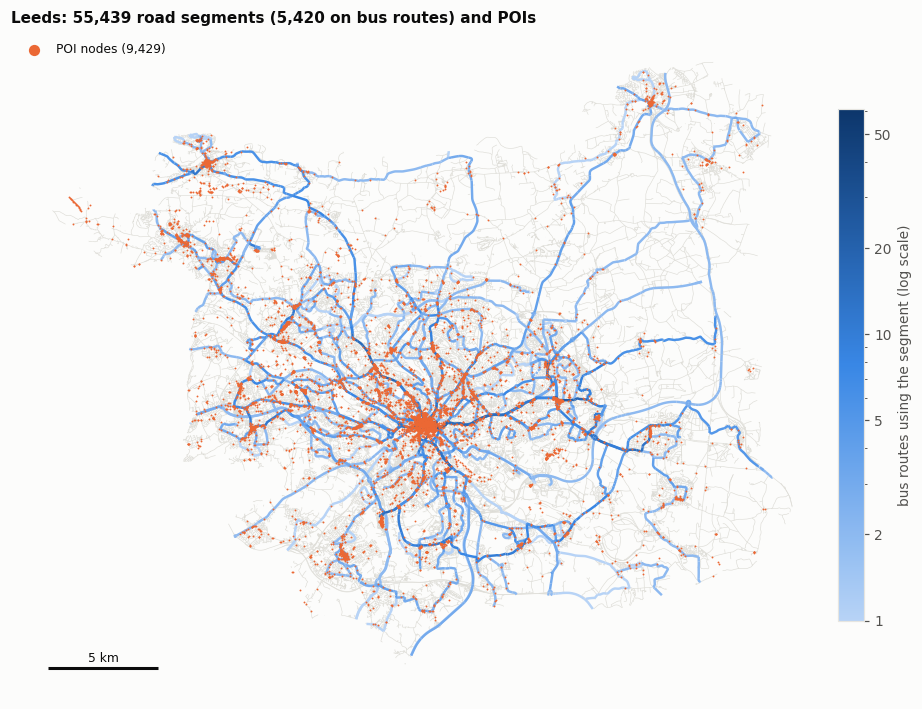

In [6]:
routes_per_seg = collections.Counter(str(w) for r in relations.values() for w in r)
bus_ids = [k for k in data if k in routes_per_seg]
other_ids = [k for k in data if k not in routes_per_seg]
ROUTES = LinearSegmentedColormap.from_list('routes', ['#b7d3f6', '#3987e5', '#0d366b'])
poi_xy = np.array([BNG.transform(e['lon'], e['lat']) for e in entities.values() if e['type'] == 'node'])

fig, ax = plt.subplots(figsize=(10, 8.5))
ax.add_collection(LineCollection([seg_xy(data[k]['points']) for k in other_ids],
                                 colors=CONTEXT, linewidths=0.4, zorder=0))
n_routes = np.array([routes_per_seg[k] for k in bus_ids])
order_bus = np.argsort(n_routes)
lc = LineCollection([seg_xy(data[bus_ids[i]]['points']) for i in order_bus], array=n_routes[order_bus],
                    cmap=ROUTES, norm=LogNorm(1, n_routes.max()), linewidths=1.6, zorder=1)
ax.add_collection(lc)
ax.scatter(poi_xy[:, 0], poi_xy[:, 1], s=1.5, color=ORANGE, lw=0, zorder=2, label=f'POI nodes ({len(poi_xy):,})')
ax.autoscale_view(); ax.set_aspect('equal'); clean_axes(ax)
cb = plt.colorbar(lc, ax=ax, fraction=0.03, pad=0.01, label='bus routes using the segment (log scale)')
ticks = [t for t in [1, 2, 5, 10, 20, 50] if t <= n_routes.max()]
cb.set_ticks(ticks); cb.set_ticklabels(ticks)
ax.legend(loc='upper left', markerscale=6, fontsize=8)
ax.set_title(f'{CITY}: {len(data):,} road segments ({len(bus_ids):,} on bus routes) and POIs', loc='left')
scale_bar(ax)
plt.show()

---
# 7. Training

The training loss of each stage, against two reference lines: **random guessing** (every candidate scored the same) and the **theoretical floor** (true partners identical, decoys opposite; it cannot actually be reached, but it shows the scale). Stages 1 and 2 report the sum of 4 quizzes per step. Stage 3's quiz size varies, so its guessing level is estimated by re-running its pairing rule on shuffled windows of streets.

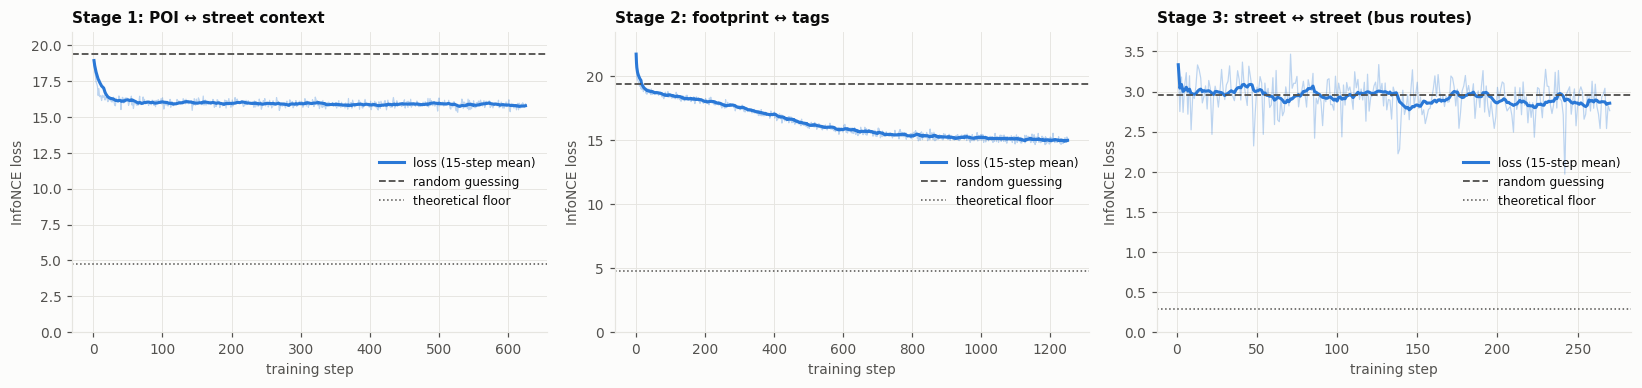

,steps,guessing,floor,"loss, last 25 steps",way from guessing to floor
Stage 1: POI ↔ street context,625,19.38,4.79,15.77,25%
Stage 2: footprint ↔ tags,1250,19.38,4.79,14.96,30%
Stage 3: street ↔ street (bus routes),270,2.95,0.29,2.85,4%


In [7]:
def read_losses(path):
    # train.log has a "(Stage name)" header before each stage, then one "Step N Loss: x" line per step.
    losses, stage = {}, None
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('(') and line.endswith(')'):
                stage = line[1:-1]
                losses[stage] = []
            elif line.startswith('Step ') and stage:
                losses[stage].append(float(line.split('Loss: ')[1]))
    return losses

def stage3_pairs(window, hub):
    # The positive pairs train_SS_rel builds from one window of road segments (same greedy rule, faster).
    paired, used_values, pairs = set(), set(), []
    candidates = [k for k in window if k in hub]
    for q in candidates:
        if hub[q] in used_values or q in paired:
            continue
        for k in candidates:
            if k != q and k not in paired and abs(hub[q] - hub[k]) <= config.hub_threshold:
                pairs.append((q, k)); paired.update((q, k)); used_values.update((hub[q], hub[k]))
                break
    return pairs

def infonce_reference(n_pairs, quizzes_per_step=1, temperature=0.5):
    # Loss if all similarities are equal (pure guessing), and the floor (partners identical, decoys opposite).
    n = np.asarray(n_pairs, dtype=float)
    chance = np.log(2 * n - 1)
    floor = np.log(1 + (2 * n - 2) * np.exp(-2 / temperature))
    return quizzes_per_step * chance.mean(), quizzes_per_step * floor.mean()

text_losses = read_losses(Path(TEXT_LOG) / 'Model' / 'train.log')
losses = {'Infomax': text_losses['Infomax'],
          'Polygon': read_losses(Path(MODEL) / 'Model' / 'train.log')['Polygon'],
          'Relation Contrastive Learning': text_losses['Relation Contrastive Learning']}

hub = {k: v / max(routes_per_seg.values()) for k, v in routes_per_seg.items()}
rng = np.random.default_rng(SEED)
seg_keys = np.array(list(data))
n_pairs = [len(stage3_pairs(perm[i:i + config.index_rel], hub))
           for perm in (seg_keys[rng.permutation(len(seg_keys))] for _ in range(3))
           for i in range(0, len(perm) - config.index_rel + 1, config.index_rel)]

STAGES = {  # log name: (label, reference losses)
    'Infomax': ('Stage 1: POI ↔ street context', infonce_reference([config.index], config.bs // config.index)),
    'Polygon': ('Stage 2: footprint ↔ tags', infonce_reference([config.index_raster], config.bs_raster // config.index_raster)),
    'Relation Contrastive Learning': ('Stage 3: street ↔ street (bus routes)', infonce_reference(n_pairs)),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
rows = {}
for ax, (stage, (label, (chance, floor))) in zip(axes, STAGES.items()):
    y = np.array(losses[stage])
    x = np.arange(1, len(y) + 1)
    ax.plot(x, y, color=BLUE, lw=0.8, alpha=0.3)
    ax.plot(x, pd.Series(y).rolling(15, min_periods=1).mean(), color=BLUE, lw=2, label='loss (15-step mean)')
    ax.axhline(chance, color=INK2, lw=1.2, ls='--', label='random guessing')
    ax.axhline(floor, color=INK2, lw=1, ls=':', label='theoretical floor')
    ax.set(xlabel='training step', ylabel='InfoNCE loss', ylim=(0, max(y.max(), chance) * 1.08))
    ax.set_title(label, loc='left')
    ax.legend(loc='center right', fontsize=8)
    last = y[-25:].mean()
    rows[label] = {'steps': len(y), 'guessing': chance, 'floor': floor, 'loss, last 25 steps': last,
                   'way from guessing to floor': (chance - last) / (chance - floor)}
plt.tight_layout(); plt.show()
pd.DataFrame(rows).T.style.format('{:.2f}').format('{:.0f}', subset=['steps']).format('{:.0%}', subset=['way from guessing to floor'])

**Reading.** Stage 1 gets 25% of the way from guessing to the floor and stage 2 30%, and both have nearly levelled off by the end. Stage 3 ends just below guessing (4%): pairing streets by their number of bus routes teaches the model very little.

---
# 8. POI embeddings (text side)

## 8a. Can the model recognise a street from its POIs?

The stage-1 quiz, run on the final model with a fixed random sample: 20 quizzes of 64 road segments. Each segment contributes one query entity and its context, and each query has to pick out its own context among the 64.

* **Training-style**: exactly the training task. The query is a random entry from the context (or "context: none") and **stays in** the context, so spotting the same string is enough to do well.
* **POI held out**: the query is a POI node and is **removed** from the context. This is the fairer test: can the model tell which street a POI belongs to from the *other* things on that street?

All strings are read without names, as the current model reads them. Besides guessing, there are two baselines: **tag matching** (no model: pick the context with the highest share of entries with exactly the query's tag string) and **untuned BERT** (the same averaging with the original BERT, so the difference from CityFM is what training added).

training-style, top-1: CityFM - untuned BERT = +5.2% (standard error 1.1%)
training-style, top-5: CityFM - untuned BERT = +10.5% (standard error 1.2%)
POI held out, top-1: CityFM - untuned BERT = +2.8% (standard error 0.7%)
POI held out, top-5: CityFM - untuned BERT = +9.1% (standard error 1.3%)


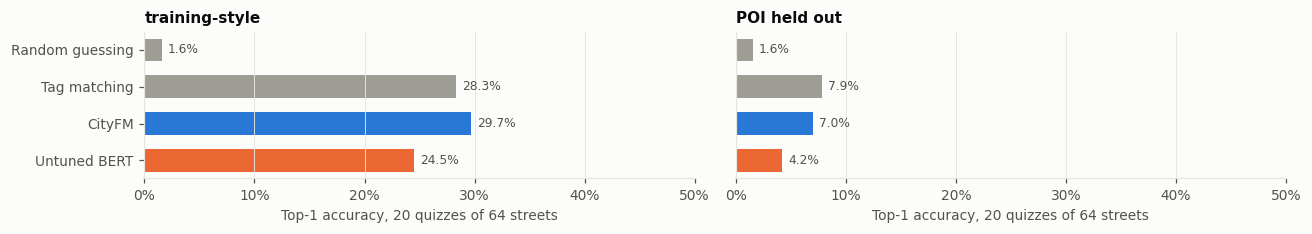

In [8]:
N_BATCHES, BATCH = 20, config.index  # 20 quizzes of 64, the quiz size used in training

def context_embedding(lm, proj, ents, add_zero=True):
    # SSModel.forward(task='info_max'): BERT states averaged over entities, then over token positions
    # (padding included), then projected. Identical rows give identical BERT outputs, so each unique
    # row is encoded once and weighted by its count. add_zero appends "context: none", as training does.
    ids = np.array(serialize_data(ents, tok, add_zero=add_zero))
    rows_, counts = np.unique(ids, axis=0, return_counts=True)
    rows_ = torch.tensor(rows_)
    h = lm(rows_, attention_mask=(rows_ != 0).long())[0]
    w = torch.tensor(counts / counts.sum(), dtype=h.dtype)[:, None, None]
    return proj((h * w).sum(0).mean(0)).numpy()

def stage1_quiz(variant, seed):
    # For N_BATCHES * BATCH road segments: the query entity id (None = "context: none") and the context ids.
    rng = np.random.default_rng(seed)
    if variant == 'training-style':
        pool = list(data)
    else:
        pool = [k for k in data if len(data[k]['context']) >= 2 and
                any(entities_in[c]['type'] == 'node' for c in data[k]['context'] if c in entities_in)]
    segs = rng.choice(pool, N_BATCHES * BATCH, replace=False)
    queries, contexts = [], []
    for k in segs:
        c = [x for x in data[k]['context'] if x in entities_in]
        if variant == 'training-style':
            r = rng.integers(0, len(c) + 1)  # as train_SS_im: any context entry, or "context: none"
            q = None if r == len(c) else c[r]
        else:
            q = rng.choice([x for x in c if entities_in[x]['type'] == 'node'])
            c = [x for x in c if x != q]
        queries.append(q); contexts.append(c)
    return segs, queries, contexts

def quiz_ranks(q_emb, c_emb):
    # Rank of each query's own partner among the BATCH candidates in its quiz (0 = picked first).
    ranks = []
    for b in range(N_BATCHES):
        s = slice(b * BATCH, (b + 1) * BATCH)
        sim = l2(q_emb[s]) @ l2(c_emb[s]).T
        ranks.append((sim > np.diag(sim)[:, None]).sum(1))
    return np.concatenate(ranks)

def tag_match_accuracy(queries, contexts):
    # No model: pick the context with the highest share of entries whose tag string equals the query's.
    acc = []
    for b in range(N_BATCHES):
        idx = range(b * BATCH, (b + 1) * BATCH)
        bags = [collections.Counter([tag_string(entities_in[c]) for c in contexts[j]] + [config.no_context]) for j in idx]
        sizes = np.array([sum(bag.values()) for bag in bags])
        for pos, i in enumerate(idx):
            qs = tag_string(entities_in[queries[i]]) if queries[i] else config.no_context
            score = np.array([bag[qs] for bag in bags]) / sizes
            best = score == score.max()
            acc.append(best[pos] / best.sum())  # ties split evenly
    return np.mean(acc)

d = config.lm_hidden_sizes['bert']
quiz1, ranks1 = {}, {}
for v_i, variant in enumerate(['training-style', 'POI held out']):
    segs, queries, contexts = stage1_quiz(variant, seed=[SEED, v_i])
    def encode():
        cols = []
        for lm, proj in ENCODERS.values():
            cols.append(np.stack([context_embedding(lm, proj, [entities_in[q]] if q else [], add_zero=False) for q in queries]))
            cols.append(np.stack([context_embedding(lm, proj, [entities_in[c] for c in ctx_]) for ctx_ in contexts]))
        return np.concatenate(cols, axis=1)
    emb = cached(f'{TAG}_stage1_quiz_{variant.replace(" ", "_")}', [f'{s}|{q}' for s, q in zip(segs, queries)], encode)
    res = {'Random guessing': {'top-1': 1 / BATCH, 'top-5': 5 / BATCH, 'median rank': BATCH / 2},
           'Tag matching': {'top-1': tag_match_accuracy(queries, contexts), 'top-5': np.nan, 'median rank': np.nan}}
    for m, name in enumerate(ENCODERS):
        r = ranks1[(variant, name)] = quiz_ranks(emb[:, 2 * m * d:(2 * m + 1) * d], emb[:, (2 * m + 1) * d:(2 * m + 2) * d])
        res[name] = {'top-1': (r == 0).mean(), 'top-5': (r < 5).mean(), 'median rank': np.median(r) + 1}
    quiz1[variant] = pd.DataFrame(res).T

for variant in quiz1:
    for k in [1, 5]:
        diff = (ranks1[(variant, 'CityFM')] < k).astype(float) - (ranks1[(variant, 'Untuned BERT')] < k)
        print(f'{variant}, top-{k}: CityFM - untuned BERT = {diff.mean():+.1%} (standard error {diff.std(ddof=1) / np.sqrt(len(diff)):.1%})')

fig, axes = plt.subplots(1, 2, figsize=(12, 2.2), sharex=True)
for ax, (variant, t) in zip(axes, quiz1.items()):
    ax.barh(t.index, t['top-1'], color=[MODEL_COLOURS.get(n, OTHER) for n in t.index], height=0.6)
    for i, v in enumerate(t['top-1']):
        ax.annotate(f'{v:.1%}', (v, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_xlim(0, 0.5)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel(f'Top-1 accuracy, {N_BATCHES} quizzes of {BATCH} streets')
    ax.set_title(variant, loc='left')
    if ax is axes[1]:
        ax.tick_params(left=False); ax.set_yticklabels([])
plt.tight_layout(); plt.show()
pd.concat(quiz1, names=['quiz', 'method']).style.format('{:.1%}', na_rep='').format('{:.0f}', subset=['median rank'], na_rep='')

**Reading 8a.** With the POI held out, CityFM finds the right street 7.0% of the time and has it in its top 5 23% of the time, against 4.2% and 14.3% for untuned BERT and 4.9% for tag matching. The gains over BERT are about four (top-1) and seven (top-5) times their standard errors, so stage 1 has learned something real from types and context alone. (v4, which read names, scored 13.9% here, mostly by recognising place names.) On the training-style quiz, plain tag matching still does best (37.8%), because the query sits in its own context; CityFM (29.7%) beats untuned BERT (24.5%).

## 8b. How POIs are arranged

Every distinct POI string the current model reads is encoded with it (`encoder.encode_nodes`) and with untuned BERT. A POI's embedding depends only on that string, and without names every POI of the same type reads the same, so the 9,429 POIs come down to a few hundred distinct strings. A *category* is the first of `amenity, shop, tourism, leisure, office, healthcare, sport` a POI has (e.g. `amenity=cafe`).

In [9]:
CAT_KEYS = ['amenity', 'shop', 'tourism', 'leisure', 'office', 'healthcare', 'sport']

def primary_category(tags):
    for k in CAT_KEYS:
        if k in tags:
            return k, f'{k}={tags[k]}'
    return None, None

ent_rows = []
for eid, e in entities.items():
    key, cat = primary_category(e['tags'])
    ent_rows.append(dict(id=eid, type=e['type'], lat=e['lat'], lon=e['lon'], key=key, category=cat,
                         name=e['tags'].get('name'), building=e['tags'].get('building'),
                         area=e.get('area', np.nan), text=tag_string(e), text_noname=tag_string(without_name(e))))
ents = pd.DataFrame(ent_rows)
nodes = ents[ents.type == 'node'].reset_index(drop=True)
polys = ents[ents.type == 'polygon'].reset_index(drop=True)

def encode_untuned_bert(ent_list):
    # Same strings, tokeniser and mean pooling as encode_nodes, but untuned BERT and no projection.
    out = []
    for e in ent_list:
        ids = torch.tensor(serialize_data([e], tok))
        out.append(bert(ids, attention_mask=(ids != 0).long())[0].squeeze(0).mean(0))
    return torch.stack(out).numpy()

# One row per unique tag string. The same string means the same category, so labels are well defined.
poi = nodes.drop_duplicates('text').reset_index(drop=True)
reps = [entities[i] for i in poi.id]
E = {'CityFM': cached(f'{TAG}_poi', poi.id, lambda: encode_nodes(MODEL, reps)[1].numpy()),
     'Untuned BERT': cached('poi_bert' if config.names_in_text else 'poi_bert_noname', poi.id, lambda: encode_untuned_bert(reps))}
Z = {k: l2(v) for k, v in E.items()}

# Name-stripped strings, for the category-level comparison in 8c.
noname = poi.drop_duplicates('text_noname')
nn_row = {t: k for k, t in enumerate(noname.text_noname)}
E_nn = {'CityFM': cached(f'{TAG}_poi_noname', noname.id,
                         lambda: encode_nodes(MODEL, [without_name(entities[i]) for i in noname.id])[1].numpy()),
        'Untuned BERT': cached('poi_bert_noname', noname.id,
                               lambda: encode_untuned_bert([without_name(entities[i]) for i in noname.id]))}
Zn = {k: l2(v[poi.text_noname.map(nn_row).values]) for k, v in E_nn.items()}
print(f'{len(nodes):,} POI nodes: {len(poi):,} distinct strings as the model reads them, {len(noname):,} once names are removed')

v5_poi: encoded (470, 768) in 15s
9,429 POI nodes: 470 distinct strings as the model reads them, 470 once names are removed


**8b.** UMAP squeezes the 768 numbers into two for plotting, keeping similar strings close together. Colours show the top-level OSM key.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


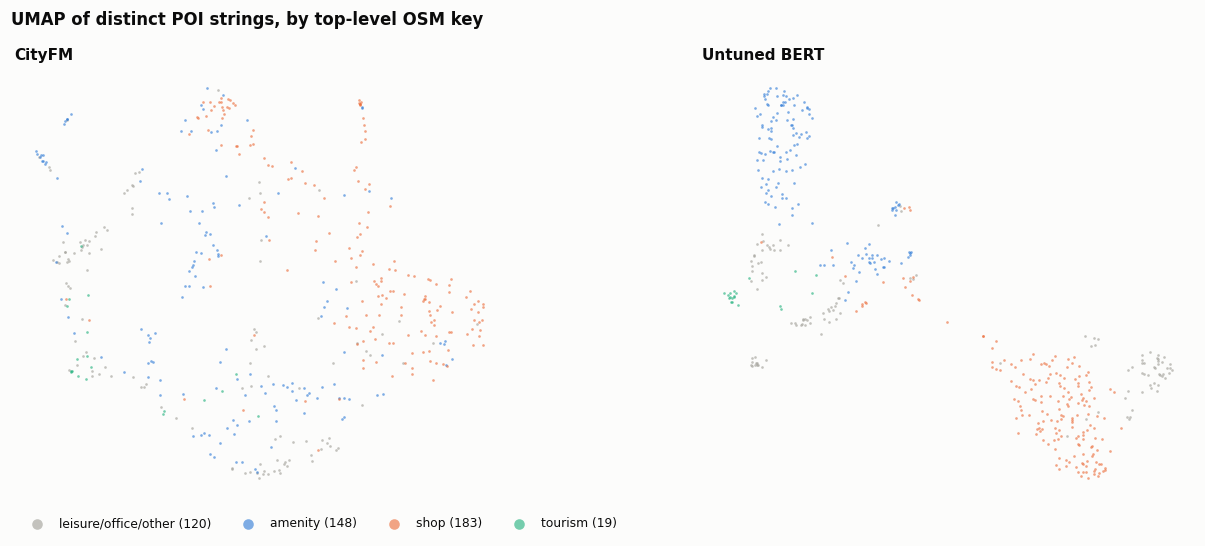

In [10]:
reducer_kw = dict(n_neighbors=30, min_dist=0.1, metric='cosine', random_state=SEED)
U = {name: umap.UMAP(**reducer_kw).fit_transform(z) for name, z in Z.items()}
KEY_COLOURS = {'amenity': BLUE, 'shop': ORANGE, 'tourism': AQUA}
group = poi.key.where(poi.key.isin(KEY_COLOURS), 'other')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, u) in zip(axes, U.items()):
    for g, colour in [('other', OTHER), *KEY_COLOURS.items()]:
        m = (group == g).values
        ax.scatter(u[m, 0], u[m, 1], s=3, color=colour, alpha=0.6, lw=0,
                   label=f'{g} ({m.sum():,})' if g != 'other' else f'leisure/office/other ({m.sum():,})')
    ax.set_title(name, loc='left'); clean_axes(ax)
axes[0].legend(loc='upper left', bbox_to_anchor=(0, -0.02), ncol=4, markerscale=4, fontsize=8)
fig.suptitle('UMAP of distinct POI strings, by top-level OSM key', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 8c. What the text embeddings capture

Stage 1 is meant to make things that are found together more similar. Two measures at the level of categories (for the 52 categories with at least 30 POIs), using name-free strings for both models so that they are compared fairly:

* **Spatial co-occurrence (Spearman ρ)**: how often two categories' POIs lie within 100 m of each other (compared with chance), set against how similar the two categories' embeddings are. If training worked, categories found together should be more similar under CityFM than under untuned BERT.
* **Meaning kept (Spearman ρ)**: how closely the model's similarities between categories follow untuned BERT's. BERT knows from general text that, say, cafés and bakeries are related; a high value means CityFM has kept that knowledge while adding what it learned in Leeds.

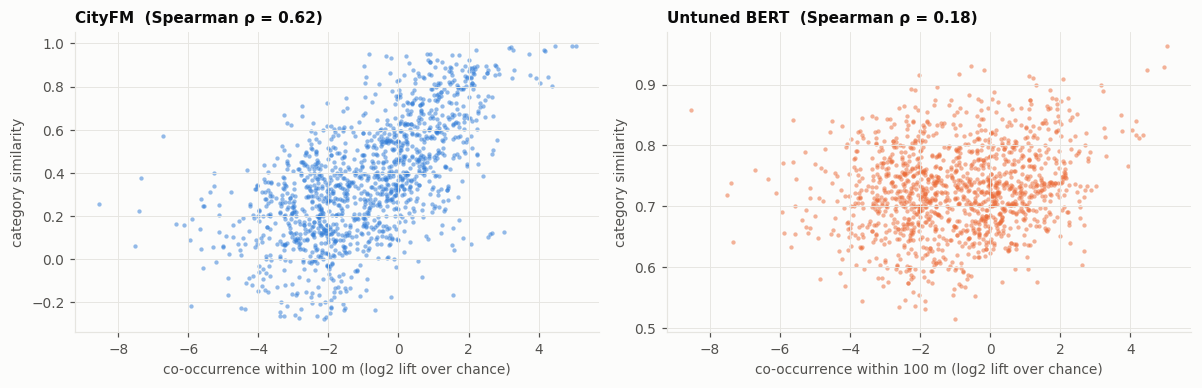

52 categories, 1326 category pairs


,CityFM,Untuned BERT
spatial co-occurrence (Spearman ρ),0.62,0.18
meaning kept: agreement with untuned BERT (Spearman ρ),0.17,1.00


In [11]:
def category_sim(z, cats, labels):
    C = np.stack([z[labels == c].mean(0) for c in cats])
    return C @ C.T

lab = poi.category.values
# Co-occurrence: pairs of POIs within 100 m, as log2 lift over random labelling of the same locations.
co_cats = nodes.category.value_counts()
co_cats = co_cats[co_cats >= 30].index.tolist()
cidx = {c: i for i, c in enumerate(co_cats)}
node_lab = nodes.category.map(cidx).fillna(-1).astype(int).values
tree = BallTree(np.radians(nodes[['lat', 'lon']].values), metric='haversine')
nbrs = tree.query_radius(np.radians(nodes[['lat', 'lon']].values), r=config.context_d / 6_371_000)
C = np.zeros((len(co_cats), len(co_cats)))
for i, js in enumerate(nbrs):
    if node_lab[i] >= 0:
        lj = node_lab[js[js != i]]
        np.add.at(C[node_lab[i]], lj[lj >= 0], 1)
n_c = np.bincount(node_lab[node_lab >= 0], minlength=len(co_cats)).astype(float)
lift = np.log2((C + 1) / (np.outer(n_c, n_c) * C.sum() / n_c.sum() ** 2 + 1))
iu = np.triu_indices(len(co_cats), 1)

cat_sim = {name: category_sim(Zn[name], co_cats, lab)[iu] for name in Zn}
text_measures = {name: {'spatial co-occurrence (Spearman ρ)': spearmanr(lift[iu], cat_sim[name]).correlation,
                        'meaning kept: agreement with untuned BERT (Spearman ρ)': spearmanr(cat_sim['Untuned BERT'], cat_sim[name]).correlation}
                 for name in Zn}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, name in zip(axes, Zn):
    ax.scatter(lift[iu], cat_sim[name], s=8, color=MODEL_COLOURS[name], alpha=0.5, lw=0)
    ax.set(xlabel=f'co-occurrence within {config.context_d} m (log2 lift over chance)', ylabel='category similarity')
    ax.set_title(f"{name}  (Spearman ρ = {text_measures[name]['spatial co-occurrence (Spearman ρ)']:.2f})", loc='left')
plt.tight_layout(); plt.show()
print(f'{len(co_cats)} categories, {len(iu[0])} category pairs')
pd.DataFrame(text_measures).round(2)

**Reading 8c.** Training has rearranged the categories around what is found together in Leeds. Categories that occur near each other are now much more similar (ρ 0.62, against 0.18 for untuned BERT). The price is much of BERT's general sense of which categories are related: CityFM's similarities agree with BERT's only weakly (ρ 0.17). The examples in 8d show what this looks like: the nearest types to a pub are now hostels, theatres, bandstands, concert venues and stadiums (places for a night out), where untuned BERT puts it next to guest houses and cafés; and "student accommodation" finds university, hostel and college.

Because the current model reads no names, every POI of a type has the same embedding, so this is a statement about *types*, not individual POIs. With names (v4), the model had instead learned to recognise places from words like *Otley* in POI names (section 2).

## 8d. Try it: nearest neighbours and free-text queries

`poi_neighbours` takes a category (`'amenity=pub'`) and lists the most similar POI strings under both models. (Without names, each string stands for every POI of that type.) `text_query` pushes any string through the CityFM text encoder. Strings phrased like the training data (`key: value`) work best; tags outside the nine the model reads (e.g. `cuisine`) never appeared in training.

In [12]:
def embed_text(s):
    # Same computation as encoder.encode_nodes, starting from a raw string.
    ids = torch.tensor([tok.tokenizer.convert_tokens_to_ids(tok.tokenizer.tokenize('[CLS] ' + s + ' [SEP]'))])
    h = model.lm(ids, attention_mask=(ids != 0).long())[0].squeeze(0)
    return model.projection_p(h.mean(0)).numpy()

assert np.allclose(np.stack([embed_text(t) for t in poi.text[:20]]), E['CityFM'][:20], atol=1e-4)

def poi_neighbours(query, k=8):
    hits = poi.index[poi.category == query] if '=' in query else poi.index[poi.text.str.contains(query, case=False)]
    if len(hits) == 0:
        raise ValueError(f'no POI string matches {query!r}')
    i = int(hits[0])
    q = poi.loc[i]
    print(f"Query: {q.text!r}")
    tables = []
    for name, z in Z.items():
        sims = z @ z[i]
        sims[i] = -np.inf
        top = np.argsort(-sims)[:k]
        t = poi.loc[top, ['text']].copy()
        t['cos'] = sims[top].round(3)
        t.columns = pd.MultiIndex.from_product([[name], t.columns])
        tables.append(t.reset_index(drop=True))
    return pd.concat(tables, axis=1)

def text_query(s, k=8):
    q = embed_text(s)
    sims = Z['CityFM'] @ (q / np.linalg.norm(q))
    top = np.argsort(-sims)[:k]
    t = poi.loc[top, ['text']].copy()
    t.insert(0, 'cos', sims[top].round(3))
    return t.reset_index(drop=True)

poi_neighbours('amenity=pub')

Query: 'amenity: pub, tourism: hostel'


CityFM         \
                                text    cos   
0                    tourism: hostel  0.885   
1                 leisure: bandstand  0.804   
2  leisure: bandstand, building: yes  0.783   
3    amenity: theatre, building: yes  0.768   
4                   amenity: theatre  0.757   
5                   leisure: concert  0.756   
6                   leisure: stadium  0.752   
7                amenity: food court  0.750   

                                        Untuned BERT         
                                                text    cos  
0                 amenity: pub, tourism: guest house  0.953  
1                 amenity: cafe, tourism: attraction  0.909  
2                 amenity: cafe, leisure: playground  0.884  
3  amenity: arts centre, shop: art, tourism: gallery  0.872  
4    amenity: cafe, shop: craft, leisure: playground  0.871  
5            amenity: post office, shop: convenience  0.870  
6                       amenity: cafe, shop: butcher  0.867  
7                   amenity: cafe, shop: convenience  0.860

In [13]:
text_query('student accommodation')

,cos,text
0,0.899,amenity: university
1,0.886,tourism: hostel
2,0.868,amenity: food court
3,0.854,amenity: college
4,0.837,office: educational institution
5,0.822,amenity: theatre
6,0.803,"amenity: theatre, building: yes"
7,0.794,amenity: bicycle parking;motorcycle parking


## 8e. The text embeddings across Leeds

Each POI's embedding is averaged within 750 m hexagons, and the hexagon averages are reduced to three components, shown as red, green and blue. Hexagons of similar colour have a similar mix of POIs; the colours themselves are arbitrary. The table names the categories whose share of POIs goes up (high end) and down (low end) with each component. Hexagons with fewer than 5 POIs are drawn as outlines. Because a POI's embedding depends only on its tags, this shows where different kinds of POI are, as the model sees them, not anything it learned about location.

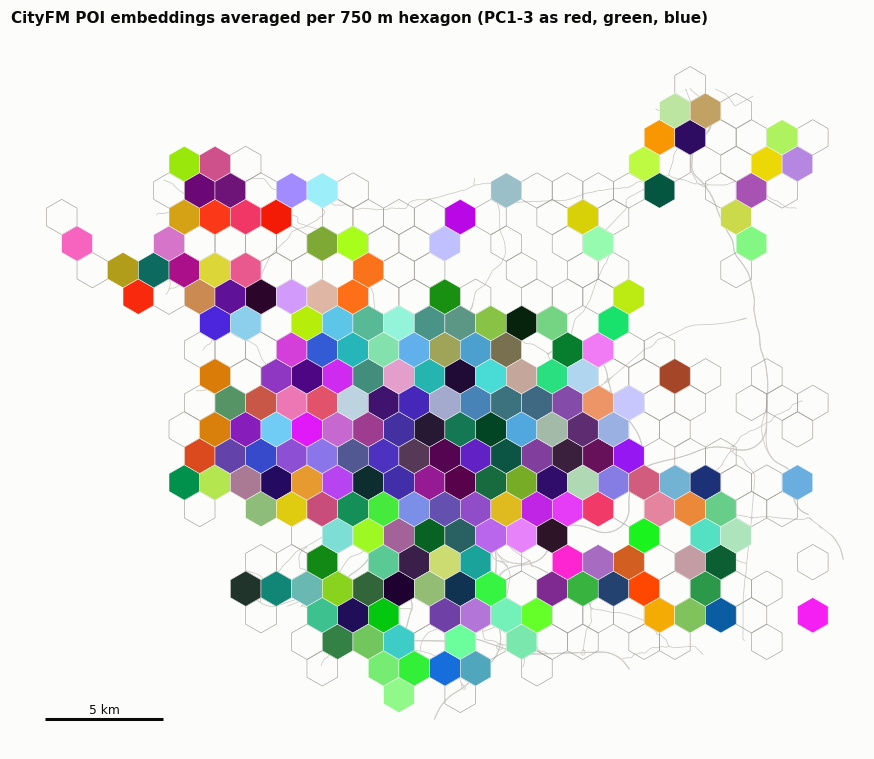

,low end,high end
"PC1 (red, 39% of variance)","fast_food, convenience, cafe, restaurant, pharmacy","information, picnic_table, public_bookcase, grit_bin, pa..."
"PC2 (green, 30% of variance)","beauty, restaurant, gift, charity, vacant","post_box, public_bookcase, post_office, kindergarten, ch..."
"PC3 (blue, 7% of variance)","information, hotel, post_box, fast_food, bank","parking, parking_space, childcare, kindergarten, picnic_..."


In [14]:
HEX_M, MIN_POIS = 750, 5

def hex_index(x, y, size):
    # Pointy-top hexagons with circumradius `size`; cube-coordinate rounding.
    q = (np.sqrt(3) / 3 * x - y / 3) / size
    r = (2 / 3 * y) / size
    s = -q - r
    rq, rr, rs = np.round(q), np.round(r), np.round(s)
    dq, dr, ds = np.abs(rq - q), np.abs(rr - r), np.abs(rs - s)
    fix_q = (dq > dr) & (dq > ds)
    fix_r = ~fix_q & (dr > ds)
    rq = np.where(fix_q, -rr - rs, rq)
    rr = np.where(fix_r, -rq - rs, rr)
    return rq.astype(int), rr.astype(int)

def hex_polygons(q, r, size):
    cx = size * np.sqrt(3) * (q + r / 2)
    cy = size * 1.5 * r
    ang = np.radians(30 + 60 * np.arange(6))
    return np.stack([np.column_stack([x + size * np.cos(ang), y + size * np.sin(ang)]) for x, y in zip(cx, cy)])

row_of = pd.Series(np.arange(len(poi)), index=poi.text)
X_nodes = Z['CityFM'][row_of[nodes.text].values]
nodes['x'], nodes['y'] = BNG.transform(nodes.lon.values, nodes.lat.values)
nodes['hq'], nodes['hr'] = hex_index(nodes.x.values, nodes.y.values, HEX_M)
hex_id = nodes.groupby(['hq', 'hr']).ngroup().values
hexes = nodes.groupby(['hq', 'hr']).size().rename('n').reset_index()
H_mean = np.zeros((len(hexes), X_nodes.shape[1]))
np.add.at(H_mean, hex_id, X_nodes)
H_mean /= hexes.n.values[:, None]
full = (hexes.n >= MIN_POIS).values
pca_hex = PCA(n_components=3, random_state=SEED).fit(H_mean[full])
S_hex = pca_hex.transform(H_mean[full])
rgb_hex = pd.DataFrame(S_hex).rank(pct=True).values  # percentile ranks, so each channel spans [0, 1] evenly
polys_hex = hex_polygons(hexes.hq.values, hexes.hr.values, HEX_M)

roads = []
for v in load_json(f'{CITY}/Data/polylines.json').values():
    if v['polyline']['tags'].get('highway') in {'motorway', 'trunk', 'primary', 'secondary'}:
        roads.append(seg_xy(v['points']))

fig, ax = plt.subplots(figsize=(10, 9.5))
ax.add_collection(LineCollection(roads, colors='#c9c8c2', linewidths=0.5, zorder=0))
ax.add_collection(PolyCollection(polys_hex[~full], facecolors='none', edgecolors=OTHER, linewidths=0.4, zorder=1))
ax.add_collection(PolyCollection(polys_hex[full], facecolors=rgb_hex, edgecolors=SURFACE, linewidths=0.3, zorder=2))
pad = 1500
ax.set_xlim(polys_hex[..., 0].min() - pad, polys_hex[..., 0].max() + pad)
ax.set_ylim(polys_hex[..., 1].min() - pad, polys_hex[..., 1].max() + pad)
ax.set_aspect('equal'); clean_axes(ax)
ax.set_title(f'CityFM POI embeddings averaged per {HEX_M} m hexagon (PC1-3 as red, green, blue)', loc='left')
scale_bar(ax)
plt.show()

share_cats = nodes.category.value_counts()
share_cats = share_cats[share_cats >= 30].index
shares = pd.crosstab(hex_id, nodes.category)[share_cats].div(hexes.n.values, axis=0).values[full]
corr = pd.DataFrame({f'PC{j + 1}': [spearmanr(S_hex[:, j], shares[:, c])[0] for c in range(len(share_cats))]
                     for j in range(3)}, index=share_cats)
pd.DataFrame({f'{pc} ({ch}, {pca_hex.explained_variance_ratio_[j]:.0%} of variance)': {
                  'low end': ', '.join(c.split('=')[1] for c in col.nsmallest(5).index),
                  'high end': ', '.join(c.split('=')[1] for c in col.nlargest(5).index)}
              for j, ((pc, col), ch) in enumerate(zip(corr.items(), ['red', 'green', 'blue']))}).T

**Reading 8e.** PC1 separates town-centre food and convenience shops (fast food, convenience stores, cafés, restaurants, pharmacies) from countryside amenities (information boards, picnic tables, grit bins). PC2 separates high-street shops (beauty, gifts, charity shops) from neighbourhood services (post boxes, public bookcases, post offices, kindergartens). So the text embeddings, averaged over an area, sort Leeds into recognisable kinds of place.

---
# 9. Building embeddings (footprint side)

A building's **footprint embedding** combines what the image network makes of its outline with its floor area. Stage 2 trains it to point at the text of the building's type. The tests use a balanced sample: up to 300 buildings from each of the 18 most common classes (a building's class is its POI category if it has one, otherwise its `building=` value; `building=yes` is left out). Chance is 1 in 18.

In [15]:
PER_CLASS, N_CLASSES = 300, 18
polys['cls'] = polys.category.fillna('building=' + polys.building.fillna('?'))
cls_counts = polys.cls.value_counts().drop(['building=yes', 'building=?'], errors='ignore')
CLASSES = cls_counts.index[:N_CLASSES].tolist()
bld = (polys[polys.cls.isin(CLASSES)]
       .groupby('cls', group_keys=False)
       .apply(lambda g: g.sample(min(len(g), PER_CLASS), random_state=SEED)))
bld = bld[[rasterisable(i) for i in bld.id]].reset_index(drop=True)
yb = bld.cls.values

def text_visual(ents_):
    _, text, vis = encode_polygons(MODEL, ents_)
    return np.concatenate([text.numpy(), vis.numpy()], axis=1)

tv = cached(f'{TAG}model_buildings_text_visual', bld.id, lambda: text_visual([entities[i] for i in bld.id]))
Bt, Bv = l2(tv[:, :768]), l2(tv[:, 768:])
print(f'{len(bld):,} buildings in {len(CLASSES)} classes')
bld.cls.value_counts().to_frame('n').T

5,269 buildings in 18 classes


,building=semidetached_house,building=school,amenity=place_of_worship,amenity=pub,amenity=school,building=apartments,building=bungalow,building=commercial,building=detached,amenity=parking,building=farm_auxiliary,building=garages,building=house,building=industrial,building=residential,building=retail,amenity=fast_food,building=farm
n,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,243,226


**9a.** Four tests of the footprint embedding:

* **Class from 10 neighbours**: the class predicted from the 10 most similar footprint embeddings.
* **Class from footprint + area**: a cross-validated linear classifier on the footprint embedding plus log floor area.
* **Zero-shot match to class text**: each footprint is assigned to the class whose average *text* embedding it is closest to. Nothing is trained for this; it asks whether footprints and texts line up in the shared space.
* **Stage-2 quiz**: 20 quizzes of 64 buildings with distinct (name-free) texts, as in training. Each footprint must pick its own text.

Baselines: **floor area alone**, and the ImageNet image network **before any training** (its 512 outline numbers, no area).

In [16]:
@contextmanager
def raster_mode(metric):
    # poly_to_raster reads config.raster_metric; read_model sets it to match the model it loads.
    old = config.raster_metric
    config.raster_metric = metric
    try:
        yield
    finally:
        config.raster_metric = old

def resnet_features(cv, metric=True):
    with raster_mode(metric):
        imgs = np.stack([poly_to_raster(Polygon(entities[i]['points'])) for i in bld.id]).astype(np.float32)
    return np.concatenate([cv(torch.tensor(imgs[s:s + 128])).flatten(1).numpy() for s in range(0, len(imgs), 128)])

def imagenet_cv():
    torch.manual_seed(SEED)
    return SSModel(CITY, config.lm, 768).cv.eval()

folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
log_area = np.log(bld[['area']].values)

def linear_probe(X):
    # Multinomial logistic regression, 5-fold cross-validated accuracy.
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
    return cross_val_score(clf, X, yb, cv=folds).mean()

def reduce(X):
    return PCA(50, random_state=SEED).fit_transform(l2(X))

# Stage-2 quiz: 64 polygons with distinct name-free texts per quiz, as in training.
polygon_ids = [k for k, e in entities.items() if e['type'] == 'polygon' and len(e['points']) > 3]
def quiz_sample(text_of):
    rng = np.random.default_rng(SEED)
    out = []
    for _ in range(N_BATCHES):
        seen, batch = set(), []
        for i in rng.permutation(len(polygon_ids)):
            k = polygon_ids[i]
            s = text_of(entities[k])
            if s not in seen and rasterisable(k):
                seen.add(s); batch.append(k)
                if len(batch) == BATCH:
                    break
        out += batch
    return out

quiz2_types = quiz_sample(lambda e: tag_string(without_name(e)))
q_types = cached(f'{TAG}model_stage2_quiz_types', quiz2_types,
                 lambda: text_visual([without_name(entities[k]) for k in quiz2_types]))
cv_imagenet = cached('imagenet_footprint_features', bld.id, lambda: resnet_features(imagenet_cv()))

P = l2(np.stack([Bt[yb == c].mean(0) for c in CLASSES]))  # class text prototypes
zs_scores = Bv @ P.T
zs_pred = np.array(CLASSES)[zs_scores.argmax(1)]
top1 = lambda q: (quiz_ranks(q[:, 768:], q[:, :768]) == 0).mean()
fp_tests = pd.DataFrame({
    'CityFM footprint embedding': {
        'class from 10 neighbours': accuracy(knn_predict(Bv, yb), yb)['accuracy'],
        'class from footprint + area': linear_probe(np.hstack([reduce(Bv), log_area])),
        'zero-shot match to class text': (zs_pred == yb).mean(),
        'stage-2 quiz (top-1)': top1(q_types)},
    'Floor area alone': {
        'class from 10 neighbours': accuracy(knn_predict(log_area, yb, metric='euclidean'), yb)['accuracy'],
        'class from footprint + area': linear_probe(log_area)},
    'ImageNet network, untrained (outline only)': {
        'class from 10 neighbours': accuracy(knn_predict(l2(cv_imagenet), yb), yb)['accuracy'],
        'class from footprint + area': linear_probe(np.hstack([reduce(cv_imagenet), log_area]))},
    'Chance': {'class from 10 neighbours': 1 / len(CLASSES), 'class from footprint + area': 1 / len(CLASSES),
               'zero-shot match to class text': 1 / len(CLASSES), 'stage-2 quiz (top-1)': 1 / BATCH},
})
fp_tests.style.format('{:.2f}', na_rep='')

,CityFM footprint embedding,Floor area alone,"ImageNet network, untrained (outline only)",Chance
class from 10 neighbours,0.57,0.19,0.19,0.06
class from footprint + area,0.57,0.21,0.27,0.06
zero-shot match to class text,0.47,,,0.06
stage-2 quiz (top-1),0.43,,,0.02


**9b.** Which classes the zero-shot match confuses. Each row is a true class, and shows where its footprints are assigned.

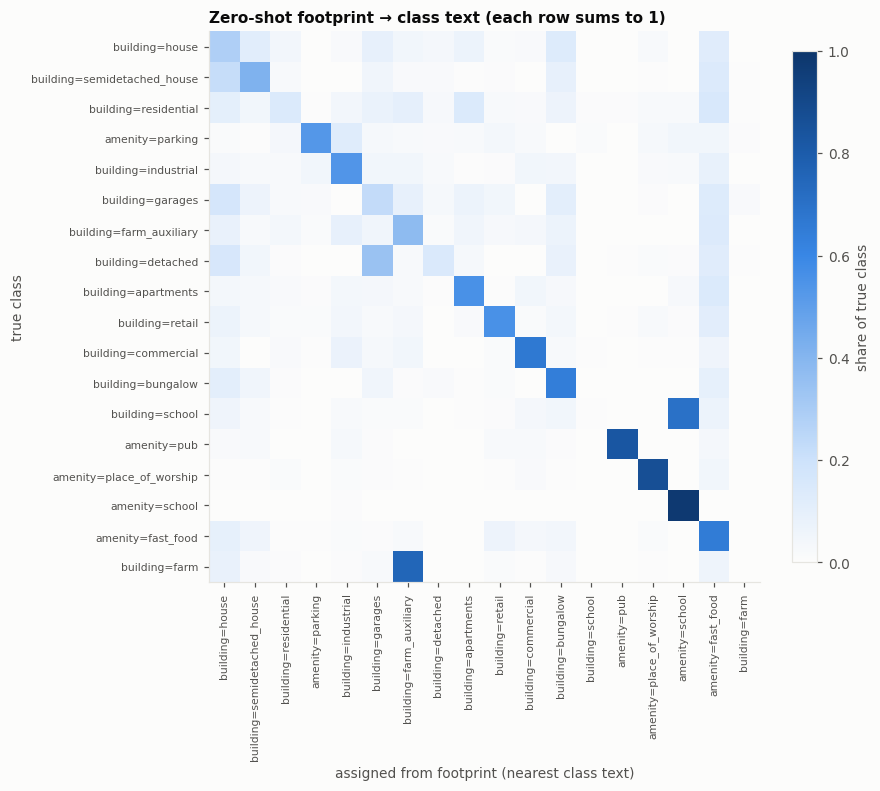

In [17]:
cm = pd.crosstab(pd.Categorical(yb, CLASSES), pd.Categorical(zs_pred, CLASSES), normalize='index', dropna=False)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm.values, cmap=BLUES, vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set(xlabel='assigned from footprint (nearest class text)', ylabel='true class'); ax.grid(False)
ax.set_title('Zero-shot footprint → class text (each row sums to 1)', loc='left')
plt.colorbar(im, ax=ax, fraction=0.04, label='share of true class')
plt.show()

**9c.** The footprint pictures the image network sees, each next to its five nearest neighbours in footprint-embedding space (with their similarity). Pictures are rotated and scaled to fill the frame, so size shows only in the area label.

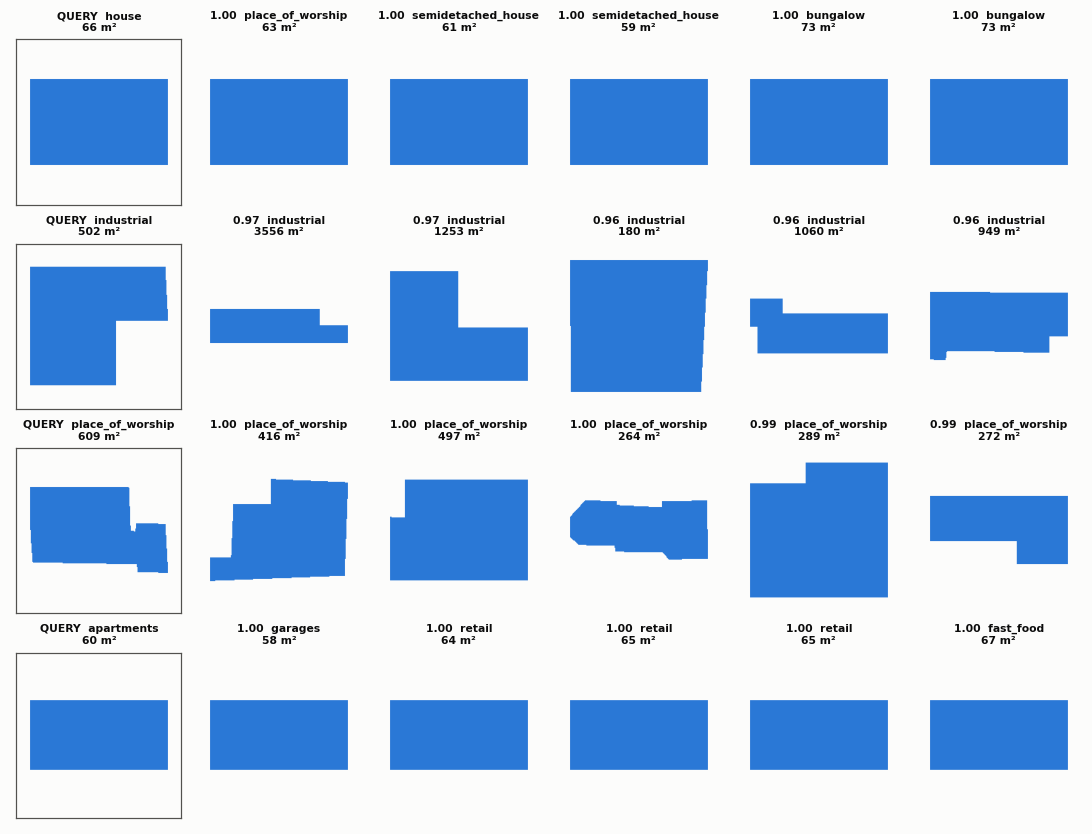

In [18]:
FP_CMAP = LinearSegmentedColormap.from_list('fp', [SURFACE, BLUE])

def footprint(i):
    return poly_to_raster(Polygon(entities[bld.id[i]]['points']))[0]

show = [bld.index[bld.cls == c][0] for c in
        ['building=house', 'building=industrial', 'amenity=place_of_worship', 'building=apartments'] if c in CLASSES]
fig, axes = plt.subplots(len(show), 6, figsize=(10, 1.9 * len(show)))
for row, qi in zip(axes, show):
    sims = Bv @ Bv[qi]; sims[qi] = -np.inf
    for j, (ax, bi) in enumerate(zip(row, [qi, *np.argsort(-sims)[:5]])):
        ax.imshow(footprint(bi), cmap=FP_CMAP, vmin=0, vmax=1)
        label = bld.cls[bi].split('=')[1]
        ax.set_title(('QUERY  ' if j == 0 else f'{sims[bi]:.2f}  ') + f'{label}\n{bld.area[bi]:.0f} m²', fontsize=7)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(j == 0); s.set_color(INK2)
plt.tight_layout(); plt.show()

**Reading 9.** The footprint branch has learned building types from shape. The class can be read from the footprint embedding 57% of the time, against 19% from floor area alone or from the untrained ImageNet network, and matching footprints straight to class texts works 47% of the time (chance 6%). Pubs, places of worship and schools are matched best. Most of the remaining errors are between classes that look alike or mean much the same: the house types (house, semi-detached, detached, bungalow) and garages, `building=school` going to `amenity=school`, and farms to farm buildings. The neighbours in 9c show the same thing: similar outlines and sizes, from classes that resemble one another.

---
# 10. Population density: the first real test

Does the model help predict something it was never trained on? The test is the one the CityFM authors use: how many people live in each part of the city.

## 10.1 How the test works

**The target.** 2021 Census population density (table TS006: residents per km²) for every Census **Output Area** in Leeds. `CityFM_uk_pop.py -c Leeds` downloads it with the area boundaries from the ONS and writes `Leeds/Data/pop_density.json` in the authors' format.

**From an area to numbers.** For each area, `CityFM_pop_eval.py` collects every OSM entity inside it and turns them into features with the authors' recipe (`precompute_embs_pop_d`): the average **text** embedding of all the entities (768 numbers), the average **footprint** embedding of up to 20 sampled polygons (768) and the **position** code of the area's centre (256).

**From numbers to a prediction.** A simple linear model (**ridge regression**) predicts the **logarithm** of density. A simple model cannot memorise the training areas, and a log scale stops a few very dense student blocks from dominating (density ranges from about 10 to over 100,000 people per km²).

**Scoring on unseen neighbourhoods.** Neighbouring areas have similar densities, so areas are grouped into neighbourhoods (MSOAs, about 25 Output Areas each; or 2 km blocks for the grid below) and split into 5 groups. The model is trained on four groups and tested on the fifth, five times over (**spatial cross-validation**; `utils/spatial_cv.py`). The score is **R²**: 1 is perfect, 0 is no better than predicting the Leeds average everywhere.

**What CityFM has to beat.**

| Baseline | What it is |
|---|---|
| **9 simple counts** | counts anyone could make from OSM: entities, buildings, houses, POIs and apartment blocks (logged), the share of buildings that are houses, total and mean footprint area (each building capped at 5,000 m², as the model's own area input is), and the share of the area covered by buildings |
| **Position only** | just the position code |
| **Untuned BERT text** | the text recipe with the original BERT, before any CityFM training |

In [19]:
# Rebuild the population-density units exactly as CityFM_pop_eval.py does, from its caches.
from shapely.ops import transform

pop_d = load_json(f'{CITY}/Data/pop_density.json')
oa_geoms = [transform(BNG.transform, Polygon(v['polygon'])) for v in pop_d.values()]

def pop_cache(name):
    return np.load(CACHE / f'pop_{name}.npz', allow_pickle=True)['x']

oa_m, grid = pop_cache('oa_members'), pop_cache('grid500')
UNITS = {
    'Output Areas': pd.DataFrame({
        'members': list(oa_m), 'density': [v['population'] * 1000 for v in pop_d.values()],
        'group': [v['msoa'] for v in pop_d.values()], 'geom': oa_geoms,
        'area_km2': [g.area / 1e6 for g in oa_geoms]}),
    '500 m grid': pd.DataFrame({
        'members': list(grid[:, 3]), 'density': grid[:, 2].astype(float),
        'group': [f'{int(cx * 500 // 2000)}_{int(cy * 500 // 2000)}' for cx, cy in grid[:, :2]],
        'geom': [Polygon([(cx * 500, cy * 500), ((cx + 1) * 500, cy * 500), ((cx + 1) * 500, (cy + 1) * 500),
                          (cx * 500, (cy + 1) * 500)]) for cx, cy in grid[:, :2]],
        'area_km2': 0.25})}
# Units with no OSM entities are skipped, as in the authors' task.
UNITS = {u: df[df.members.map(len) > 0].reset_index(drop=True) for u, df in UNITS.items()}
UNIT_TAG = {'Output Areas': 'output', '500 m grid': '500'}  # cache-name tags used by CityFM_pop_eval.py
oa_pop = UNITS['Output Areas'].density * UNITS['Output Areas'].area_km2
for u, df in UNITS.items():
    print(f'{u}: {len(df):,} areas, {df.group.nunique()} neighbourhood groups, '
          f'density {df.density.quantile(.1):,.0f}-{df.density.quantile(.9):,.0f} people per km² (10th-90th percentile)')
print(f'People per Output Area: median {oa_pop.median():.0f}, 10th-90th percentile {oa_pop.quantile(.1):.0f}-{oa_pop.quantile(.9):.0f}')

Output Areas: 2,598 areas, 107 neighbourhood groups, density 1,032-12,223 people per km² (10th-90th percentile)
500 m grid: 1,593 areas, 154 neighbourhood groups, density 49-5,059 people per km² (10th-90th percentile)
People per Output Area: median 299, 10th-90th percentile 220-417


## 10.2 Two ways of dividing up the city

**10.2a.** Population density on Output Areas (left) and on a regular 500 m grid (right). Grid cells get their population from the Output Areas they overlap, in proportion to the overlap. Only cells wholly inside Leeds that contain at least one OSM entity are kept.

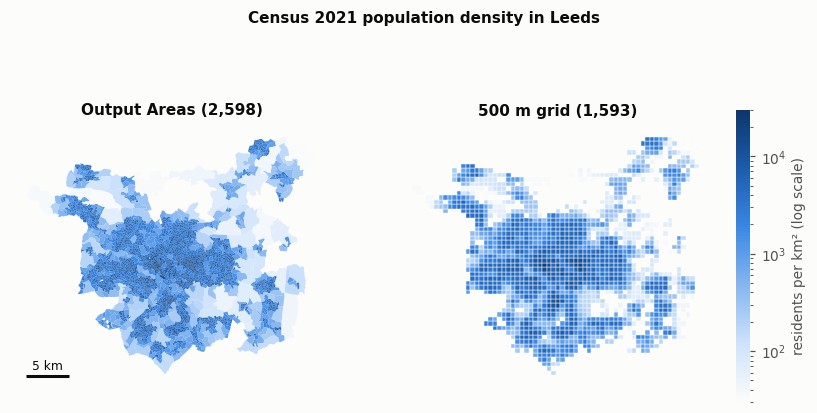

In [20]:
DENSITY_NORM = LogNorm(30, 30000)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (u, df) in zip(axes, UNITS.items()):
    pc = PolyCollection([np.asarray(g.exterior.coords) for g in df.geom], array=df.density.clip(30, 30000),
                        cmap=BLUES, norm=DENSITY_NORM, edgecolors=SURFACE if u == '500 m grid' else 'none', linewidths=0.3)
    ax.add_collection(pc)
    ax.autoscale_view(); ax.set_aspect('equal'); clean_axes(ax)
    ax.set_title(f'{u} ({len(df):,})')
cb = fig.colorbar(pc, ax=axes, shrink=0.75, pad=0.02)
cb.set_label('residents per km² (log scale)'); cb.outline.set_visible(False)
scale_bar(axes[0])
fig.suptitle('Census 2021 population density in Leeds', fontweight='bold', fontsize=10)
plt.show()

**10.2b.** Why Output Areas make a poor test: the Census draws them to hold similar numbers of people, so a small area is a dense one.

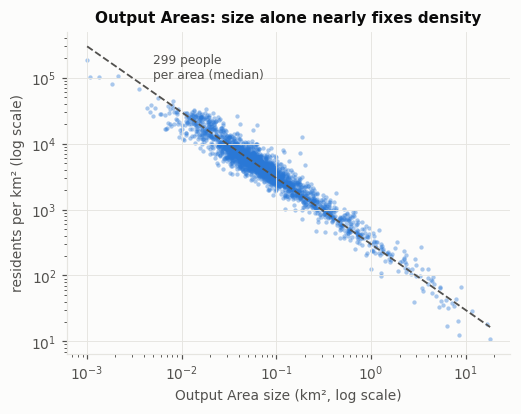

In [21]:
oa = UNITS['Output Areas']
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(oa.area_km2, oa.density, s=8, color=BLUE, alpha=0.4, linewidths=0)
a = np.logspace(np.log10(oa.area_km2.min()), np.log10(oa.area_km2.max()), 50)
ax.plot(a, oa_pop.median() / a, color=INK2, lw=1.2, ls='--')
ax.text(a[8], oa_pop.median() / a[8] * 1.6, f'{oa_pop.median():.0f} people\nper area (median)', color=INK2, fontsize=8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Output Area size (km², log scale)'); ax.set_ylabel('residents per km² (log scale)')
ax.set_title('Output Areas: size alone nearly fixes density')
plt.show()

Area size alone predicts Output Area density with R² 0.94, so any feature that tracks size gets credit without saying anything about how people live. Every 500 m grid cell has the same size, so there the only way to predict density is to recognise what is built there. **The grid is the fair test.**

## 10.3 Results

**10.3a.** R² for each set of features, on the grid (left, the fair test) and on Output Areas (right). Grey bars use no language model, orange is untuned BERT and blue is the current model. "Text + footprints + position" is the combination the authors' task uses. Each score is the average over 10 random splits into neighbourhood groups; the whiskers show the lowest and highest of the 10.

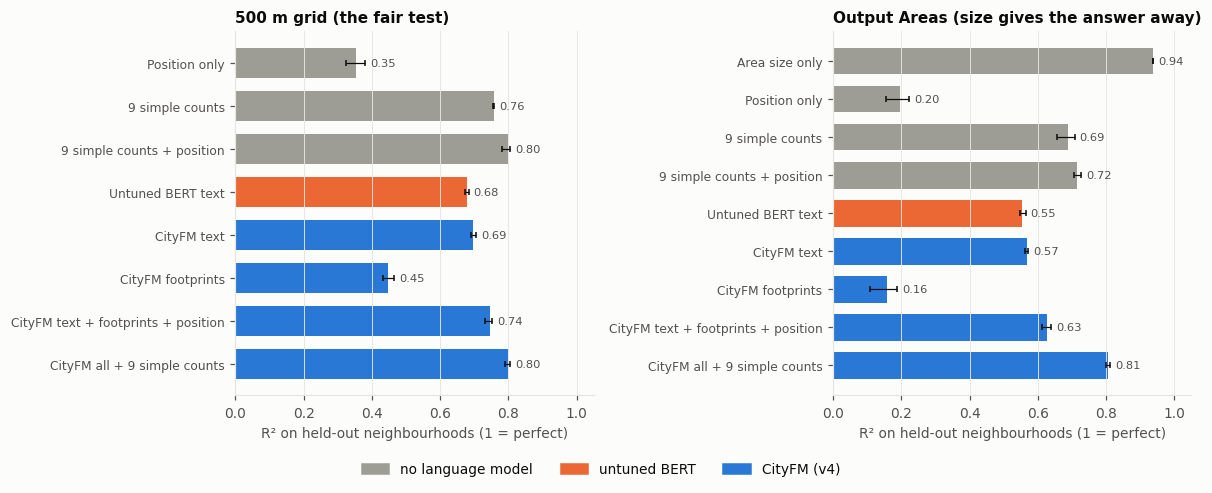

In [22]:
from joblib import Parallel, delayed
from utils.spatial_cv import spatial_cv_predict, r2

N_REPEATS = 10

def unit_features(u):
    t = UNIT_TAG[u]
    return {'hand': pop_cache(f'hand_{t}'), 'pos': pop_cache(f'pos_{t}'),
            'bert': pop_cache(f'bert_text_collapsed_{t}'),  # untuned BERT reading the same collapsed units as the model
            'area': np.log10(UNITS[u].area_km2.values.astype(float))[:, None],
            'text': pop_cache(f'text_{t}_{MODEL}'), 'footprints': pop_cache(f'visual_{t}_{MODEL}')}

def feature_sets(f, u):
    # (label, kind, features). kind sets the bar colour: no language model, untuned BERT, or CityFM.
    sets = [('Area size only', 'simple', f['area'])] if u == 'Output Areas' else []
    return sets + [
        ('Position only', 'simple', f['pos']),
        ('9 simple counts', 'simple', f['hand']),
        ('9 simple counts + position', 'simple', np.hstack([f['hand'], f['pos']])),
        ('Untuned BERT text', 'bert', f['bert']),
        ('CityFM text', 'cityfm', f['text']),
        ('CityFM footprints', 'cityfm', f['footprints']),
        ('CityFM text + footprints + position', 'cityfm', np.hstack([f['text'], f['footprints'], f['pos']])),
        ('CityFM all + 9 simple counts', 'cityfm', np.hstack([f['text'], f['footprints'], f['pos'], f['hand']]))]

def spatial_cv_r2(X, df, repeats=N_REPEATS):
    # Neighbourhoods are dealt into 5 folds at random and each fold is predicted by a ridge regression
    # fitted on the other four (utils/spatial_cv.py, also used by CityFM_pop_eval.py). Repeat r uses the
    # same folds for every feature set, so differences between feature sets are paired.
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)  # one core per job; jobs run in parallel
    y = np.log10(df.density.values + 1)
    preds = [spatial_cv_predict(X, y, df.group.values, seed=r) for r in range(repeats)]
    return np.array([r2(y, p) for p in preds]), preds[0]

path = CACHE / f'pop_cv_repeats_{TAG}.npz'
if path.exists():
    z = np.load(path, allow_pickle=True)
    pop_scores, pop_preds = z['scores'].item(), z['preds'].item()
else:
    jobs = [(u, label, kind, X) for u in UNITS for label, kind, X in feature_sets(unit_features(u), u)]
    out = Parallel(n_jobs=8)(delayed(spatial_cv_r2)(X, UNITS[u][['density', 'group']]) for u, _, _, X in jobs)
    pop_scores = {(u, label, kind): s for (u, label, kind, _), (s, _) in zip(jobs, out)}
    pop_preds = {(u, label): p for (u, label, _, _), (_, p) in zip(jobs, out)}
    np.savez(path, scores=pop_scores, preds=pop_preds)

KIND_COLOURS = {'simple': OTHER, 'bert': ORANGE, 'cityfm': BLUE}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, u in zip(axes, ['500 m grid', 'Output Areas']):
    items = [(label, kind, s) for (uu, label, kind), s in pop_scores.items() if uu == u][::-1]
    y = np.arange(len(items))
    means = np.array([s.mean() for *_, s in items])
    ax.barh(y, means, height=0.7, color=[KIND_COLOURS[k] for _, k, _ in items])
    ax.errorbar(means, y, xerr=[means - [s.min() for *_, s in items], [s.max() for *_, s in items] - means],
                fmt='none', ecolor=INK, elinewidth=0.8, capsize=2)
    for yy, m, (*_, s) in zip(y, means, items):
        ax.text(s.max() + 0.015, yy, f'{m:.2f}', va='center', fontsize=7.5, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels([label for label, *_ in items], fontsize=8)
    ax.set_xlim(0, 1.05); ax.grid(axis='y', visible=False)
    ax.set_xlabel('R² on held-out neighbourhoods (1 = perfect)')
    ax.set_title(u + (' (the fair test)' if u == '500 m grid' else ' (size gives the answer away)'), loc='left')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOURS.values()]
fig.legend(handles, ['no language model', 'untuned BERT', 'CityFM (v4)'], loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

pd.DataFrame({(u, label): {'R² (mean)': s.mean(), 'lowest': s.min(), 'highest': s.max()}
              for (u, label, _), s in pop_scores.items()}).T.style.format('{:.2f}')

**Reading 10.3a** (the grid unless stated otherwise).

* **The 9 simple counts are the bar to beat**: R² 0.76, and 0.80 with position. In Leeds almost every house is mapped, so counting buildings already tells you where people live.
* **CityFM's text is about as good as untuned BERT's** here (0.69 against 0.68). (Untuned BERT in this test reads names; the current model does not.)
* **The footprints alone reach 0.45**, a little above earlier models (0.42).
* **The authors' combination does not beat the counts.** Text + footprints + position gives 0.74: just below the counts alone, and below counts + position.
* **CityFM adds nothing on top of the counts.** Counts + position + all of CityFM's features score 0.80, the same as counts + position.
* **On Output Areas**, area size alone wins (0.94). CityFM does add to the counts there (0.81 against 0.72), probably by picking up signs of a large area, such as fields and parks. The grid, where size gives nothing away, shows no such gain.

Every model from v1 to v5 has scored 0.74-0.77 here, so none of the changes to training has moved this result.

**10.3b.** Predicted against actual density for every grid cell, on one of the 10 splits. A perfect model would put every point on the dashed line.

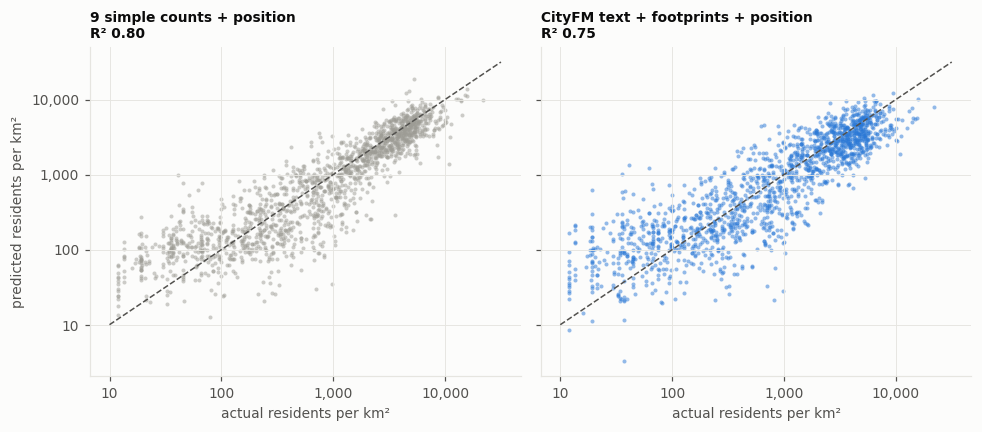

9 simple counts + position: typical miss (median) a factor of 1.51; cells under 100 people per km² over-predicted by a factor of 2.4
CityFM text + footprints + position: typical miss (median) a factor of 1.69; cells under 100 people per km² over-predicted by a factor of 2.4


In [23]:
gr = UNITS['500 m grid']
actual = np.log10(gr.density.values + 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (label, colour) in zip(axes, [('9 simple counts + position', OTHER), ('CityFM text + footprints + position', BLUE)]):
    pred = pop_preds[('500 m grid', label)]
    ax.scatter(actual, pred, s=7, color=colour, alpha=0.5, linewidths=0)
    ax.plot([1, 4.5], [1, 4.5], color=INK2, lw=1, ls='--')
    ax.set_title(f'{label}\nR² {r2(actual, pred):.2f}', loc='left', fontsize=9)
    ticks = [1, 2, 3, 4]
    ax.set_xticks(ticks); ax.set_xticklabels([f'{10 ** t:,}' for t in ticks])
    ax.set_yticks(ticks); ax.set_yticklabels([f'{10 ** t:,}' for t in ticks])
    ax.set_xlabel('actual residents per km²')
axes[0].set_ylabel('predicted residents per km²')
plt.tight_layout(); plt.show()
for label in ['9 simple counts + position', 'CityFM text + footprints + position']:
    err = pop_preds[('500 m grid', label)] - actual
    print(f'{label}: typical miss (median) a factor of {10 ** np.median(np.abs(err)):.2f}; '
          f'cells under 100 people per km² over-predicted by a factor of {10 ** np.median(err[actual < 2]):.1f}')

**Reading 10.3b.** Both do well in built-up Leeds, above about 1,000 people per km², and both struggle in the countryside, where a cell may hold a few farms, a golf course or a business park and the number of residents varies a lot for similar-looking OSM content. CityFM's typical miss is a factor of 1.69 (it predicts 1,690 or 590 where the truth is 1,000), against 1.51 for the counts, and both over-predict the emptiest cells by a factor of about 2.4.

---
# Glossary

| Term | Meaning here |
|---|---|
| **Embedding** | A fixed-length list of numbers (a vector) that represents a thing. Similar things should have similar vectors |
| **Cosine similarity** | How closely two vectors point in the same direction: 1 = same direction, 0 = unrelated. The standard way to compare embeddings |
| **Self-supervised / contrastive learning** | Training without labels by making up a task from the data itself, here "match each item to its true partner" |
| **InfoNCE loss** | The score of that matching task. Lower is better, and its value for pure guessing is known |
| **Batch, step, epoch** | A batch is one quiz's worth of items; a step is one weight update; an epoch is one pass over the (capped) training data |
| **Learning rate** | How big a change the model makes to its weights after each step |
| **Fine-tuning** | Continuing to train an already-trained model (BERT) on a new task |
| **Untuned BERT** | The same text pipeline with the original BERT. The difference from CityFM is what CityFM's training added |
| **Top-1 / top-5 accuracy** | In a 64-way quiz: how often the true partner is ranked first / in the top 5. Guessing gives 1.6% / 7.8% |
| **kNN (k-nearest neighbours)** | Predict an item's label from the labels of its k most similar items |
| **AUC** | The chance that a random "should be similar" pair scores higher than a random "should be different" pair. 0.5 = no signal, 1 = perfect |
| **Spearman ρ** | Rank correlation: do two quantities go up together? −1 to 1 |
| **UMAP / PCA** | Ways to squash 768 numbers into 2-3 for plotting. PCA is linear; UMAP keeps local neighbourhoods |
| **Zero-shot** | A prediction with no training for that task, here matching footprints to class texts directly |
| **R²** | The share of the variation in a target that the predictions explain (1 = perfect, 0 = as good as predicting the mean) |
| **Output Area, LSOA, MSOA** | Nested Census areas: Output Areas hold about 300 people in Leeds, LSOAs about 1,500 and MSOAs about 7,500 |
| **Ridge regression** | A linear model with a penalty that stops it leaning too heavily on any one feature |
| **Spatial cross-validation** | Testing a model on whole neighbourhoods it never saw in training, so it cannot score well by copying nearby areas |
| **Log scale** | A scale on which each step multiplies by the same amount (10, 100, 1,000, ...) |